In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pickle

In [24]:
PATH = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qNLP_Efficiency/qnlp_in_practice/"
rp_noise_random_path = "code/rp_runs/noise_random/"
rp_noise_pretrain_path = "code/rp_runs/noise_pretrained/"
rp_sim_random_path = "code/rp_runs/sim_random/"
rp_sim_pretrain_path = "code/rp_runs/sim_pretrained/"
mc_noise_random_path = "code/mc_runs/noise_random/"
mc_noise_pretrain_path = "code/mc_runs/noise_pretrained/"
mc_sim_random_path = "code/mc_runs/sim_random/"
mc_sim_pretrain_path = "code/mc_runs/sim_pretrained/"

# RP Experiments 

## RP Noise Experiments

In [80]:
def get_noise_data_from_path(directory_path, niter=100):
    directory_path = PATH+ directory_path
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)

        if len(data['error_history']) != niter:
            print(file.name + f" Does not have {niter} iterations!")
            break

        cost_histories[f_index, :] = data['func_history']
        error_train_histories[f_index, :] = data['error_history'] 
        error_test_histories[f_index, :] = data['test_error_list']
        iters_selected[f_index, :] = data['iters_selected']
        assert(len(data['test_error_list']) == len(data['iters_selected']))
        assert(len(data['func_history']) == len(data['error_history']))

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)

    error_test_history_mean = error_test_histories.mean(0)
    return cost_history_mean, error_train_history_mean, error_test_history_mean, iters_selected

random_cost, random_train, random_test, iters_selected = get_noise_data_from_path(rp_noise_random_path, 100)
pretrained_cost, pretrained_train, pretrained_test, iters_selected = get_noise_data_from_path(rp_noise_pretrain_path, 100)

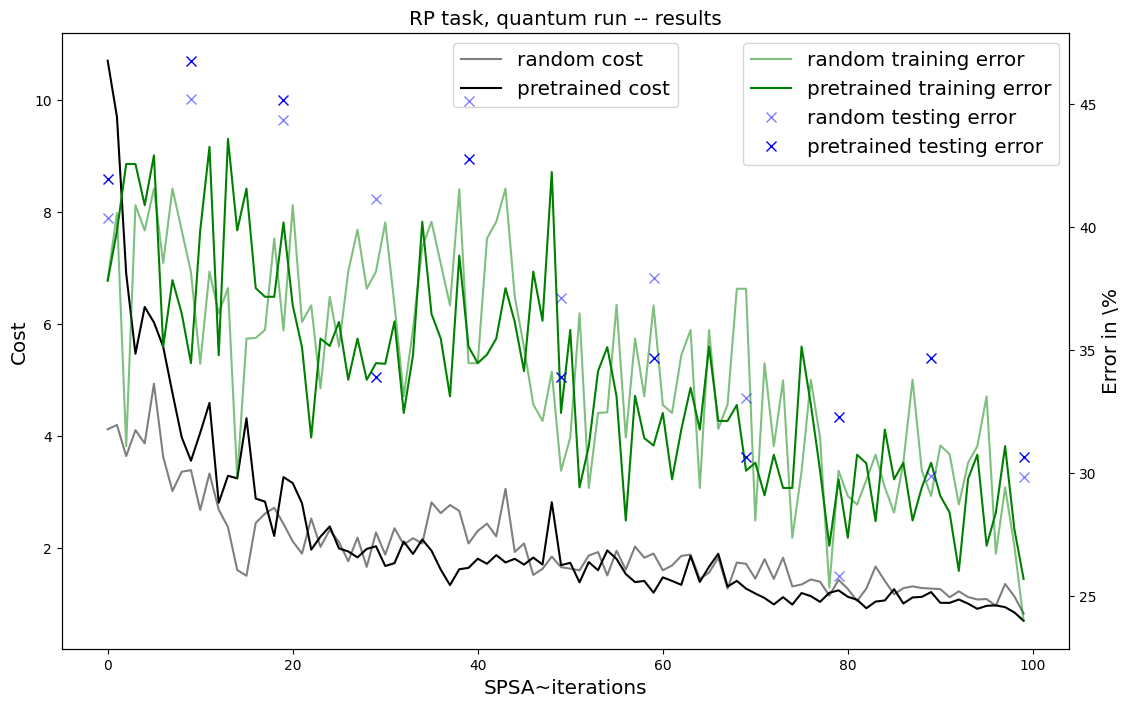

In [81]:
fig, ax1 = plt.subplots(figsize=(13, 8))

ax1.plot(range(len(random_cost)), random_cost, '-k', markersize=4, label='random cost', alpha=0.5)
ax1.plot(range(len(pretrained_cost)), pretrained_cost, '-k', markersize=4, label='pretrained cost')
ax1.set_ylabel(r"Cost", fontsize='x-large')
ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
ax1.legend(loc='upper center', fontsize='x-large')

ax2 = ax1.twinx()
ax2.set_ylabel(r"Error in \%", fontsize='x-large')
ax2.plot(range(len(random_train)), random_train, '-g', markersize=4, label='random training error', alpha=0.5)
ax2.plot(range(len(pretrained_train)), pretrained_train, '-g', markersize=4, label='pretrained training error')
ax2.plot(iters_selected[0], random_test, 'xb', markersize=7, label='random testing error', alpha=0.5)
ax2.plot(iters_selected[1], pretrained_test, 'xb', markersize=7, label='pretrained testing error')
ax2.legend(loc='upper right', fontsize='x-large')

plt.title('RP task, quantum run -- results', fontsize='x-large')
plt.show()

## RP Simulated Experiments

dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_keys(['param_history', 'func_history', 'error_history'])
dict_key

KeyboardInterrupt: 

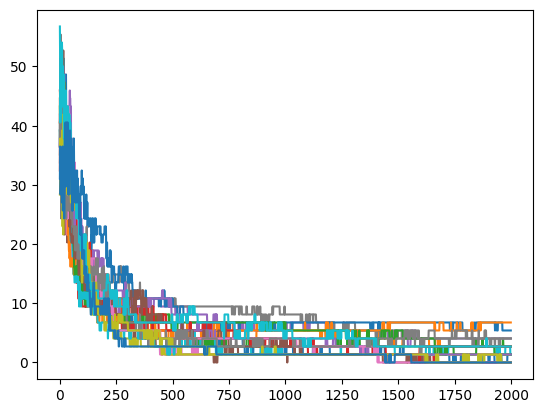

In [83]:
def get_sim_data_from_path(directory_path, niter):
    directory_path = PATH+ directory_path
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)

        if len(data['error_history']) != niter:
            print(file.name + f" Does not have {niter} iterations!")
            break
        
        cost_histories[f_index, :] = None
        error_train_histories[f_index, :] = data['error_history']
        error_test_histories[f_index, :] = None
        iters_selected[f_index, :] = None

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)
    error_test_history_mean = error_test_histories.mean(0)
    
    return cost_history_mean, error_train_history_mean, error_test_history_mean, iters_selected

random_cost, random_train, random_test, random_iters_selected = get_sim_data_from_path(rp_sim_random_path, 2000)
pretrained_cost, pretrained_train, pretrained_test, pretrained_iters_selected = get_sim_data_from_path(rp_sim_pretrain_path, 2000)

# MC Tasks

## MC Noise Experiments

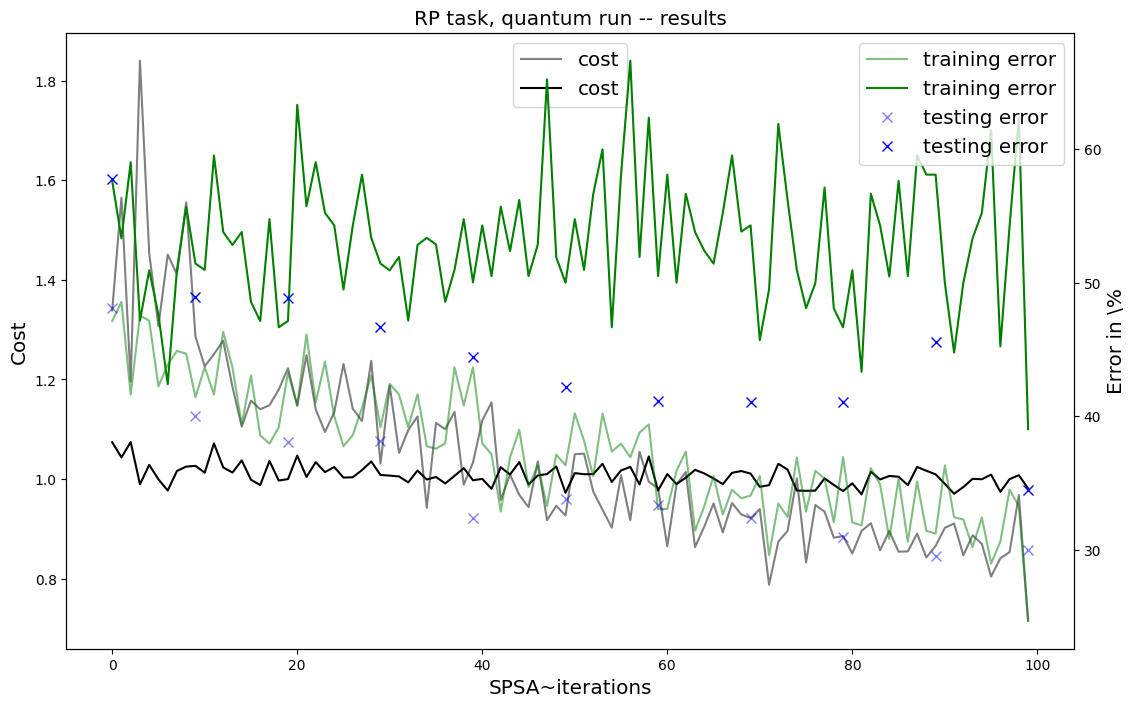

In [77]:
random_cost, random_train, random_test, iters_selected = get_noise_data_from_path(mc_noise_random_path, 100)
pretrained_cost, pretrained_train, pretrained_test, iters_selected = get_noise_data_from_path(mc_noise_pretrain_path, 100)

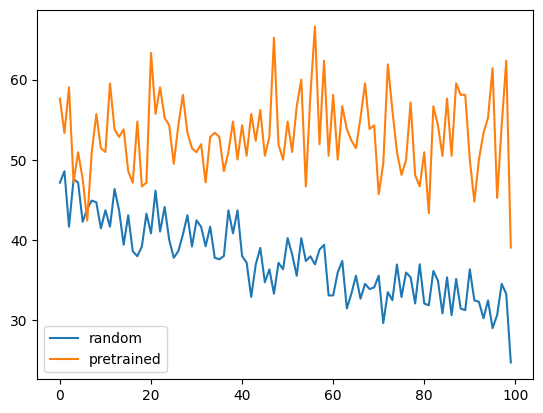

In [15]:
plt.plot(random_train, label='random')
plt.plot(pretrained_train, label='pretrained')
plt.legend()

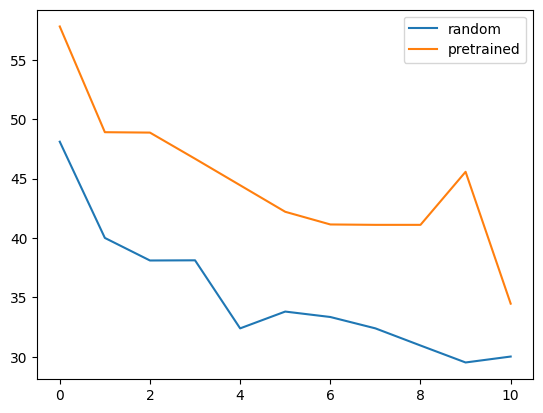

In [16]:
plt.plot(random_test, label='random')
plt.plot(pretrained_test, label='pretrained')
plt.legend()

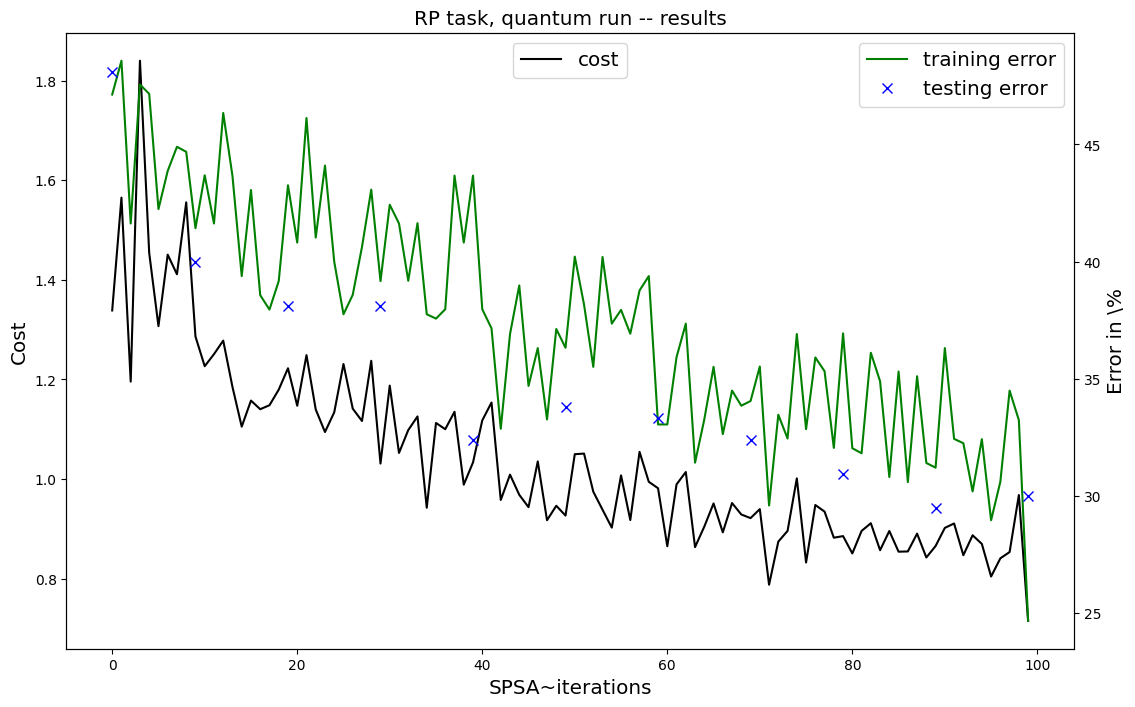

In [17]:
#****************************************************
# Summary plot
#****************************************************
from matplotlib import pyplot as plt

fig, ax1 = plt.subplots(figsize=(13, 8))

ax1.plot(range(len(random_cost)), random_cost, '-k', markersize=4, label='cost')
ax1.set_ylabel(r"Cost", fontsize='x-large')
ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
ax1.legend(loc='upper center', fontsize='x-large')

ax2 = ax1.twinx()
ax2.set_ylabel(r"Error in \%", fontsize='x-large')
ax2.plot(range(len(random_train)), random_train, '-g', markersize=4, label='training error')
ax2.plot(random_iters_selected[0], random_test, 'xb', markersize=7, label='testing error')
ax2.legend(loc='upper right', fontsize='x-large')

plt.title('RP task, quantum run -- results', fontsize='x-large')
plt.savefig('RP_task_Results_noise_pretrained.png', dpi=300, facecolor='white')  
plt.show()

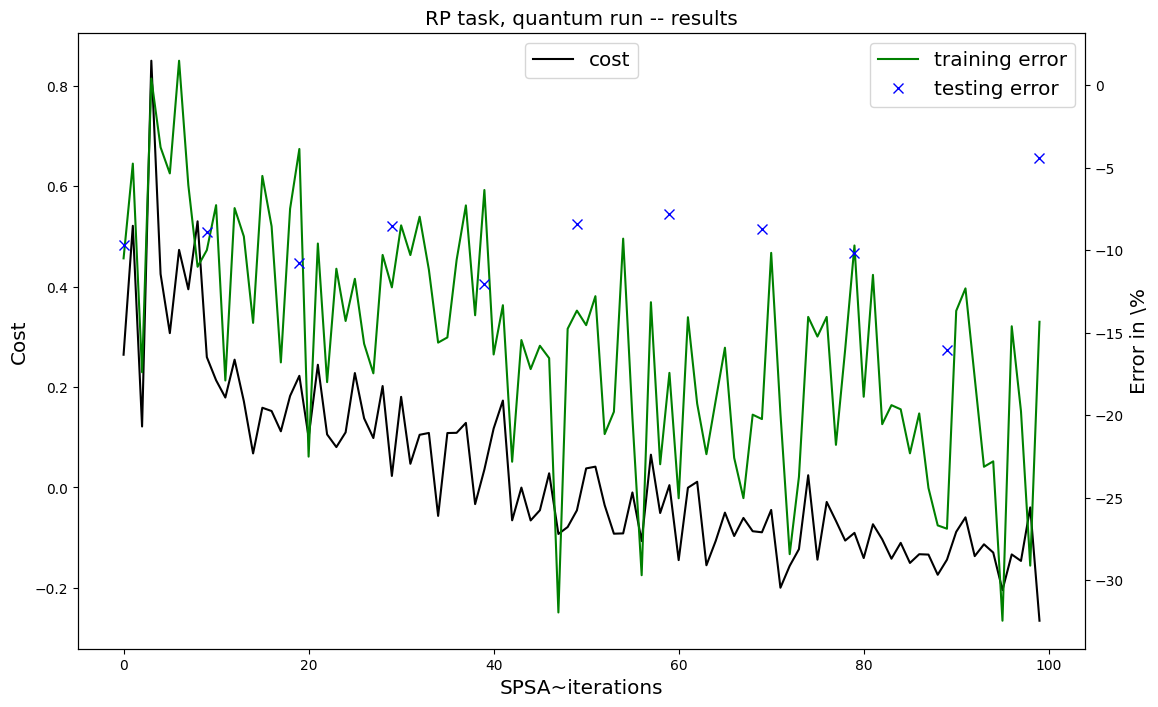

In [18]:
#****************************************************
# Summary plot
#****************************************************
from matplotlib import pyplot as plt

fig, ax1 = plt.subplots(figsize=(13, 8))

ax1.plot(range(len(pretrained_cost)), random_cost-pretrained_cost, '-k', markersize=4, label='cost')
ax1.set_ylabel(r"Cost", fontsize='x-large')
ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
ax1.legend(loc='upper center', fontsize='x-large')

ax2 = ax1.twinx()
ax2.set_ylabel(r"Error in \%", fontsize='x-large')
ax2.plot(range(len(pretrained_train)), random_train-pretrained_train, '-g', markersize=4, label='training error')
ax2.plot(pretrained_iters_selected[0], random_test-pretrained_test, 'xb', markersize=7, label='testing error')
ax2.legend(loc='upper right', fontsize='x-large')

plt.title('RP task, quantum run -- results', fontsize='x-large')
plt.savefig('RP_task_Results_noise_pretrained.png', dpi=300, facecolor='white')
plt.show()